# BAN 612 Data Analytics — Homework Assignment 3

## Import Libraries

In [102]:
import pandas as pd
from bs4 import BeautifulSoup
import requests
import re
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

## Question 1 — Remote.co Job Posting Analysis

This section collects and analyzes Remote.co search results for **Business Data Analyst** roles. Because the website did not reliably respond to the Python request, the search-results page was saved from the browser and parsed locally with BeautifulSoup.

### Set Up the Web Scraping

In [2]:
#Define URL
live_url = "https://remote.co/remote-jobs/search?searchkeyword=Business%20Data%20Analyst"

#Define Headers
headers = {
    "User-Agent": "Mozilla/5.0"
}

### Load and Parse the Saved HTML

In [3]:
with open("Business Data Analyst Jobs.html", "r", encoding="utf-8") as file:
    html = file.read()

soup = BeautifulSoup(html, "html.parser")

#### Identify the Job Cards

The selector below finds the individual job cards in the saved search-results HTML. The saved page contained **50 loaded job cards**, which is the sample analyzed in this notebook.

In [4]:
cards = soup.select("div.sc-iklnEz.hEcaTE")
len(cards)

50

In [5]:
print(cards[0].prettify()[:2000])

<div class="sc-iklnEz hEcaTE" data-index="0" data-isfreejob="false" id="35ffca01-97e4-4184-94da-de7cb5a4d42b">
 <div>
  <div class="sc-bJDGZN kRyfas">
   <div class="sc-kmrLuI fjrqia">
    <a class="sc-kBrxXP iAILIF" href="https://remote.co/job-details/business-data-analyst-35ffca01-97e4-4184-94da-de7cb5a4d42b" id="job-name-35ffca01-97e4-4184-94da-de7cb5a4d42b" rel="nofollow">
     <span class="sc-ejTmV dcczRM">
      30+ days ago
     </span>
     <span class="sc-gERzRH iybrCe">
      Business Data Analyst
     </span>
    </a>
   </div>
   <div class="sc-fqHEPX dsYZhX">
    <a aria-label="Save Job" class="sc-eBwtYi bZmQeg fa fa-regular fa-heart" href="https://remote.co/remote-jobs/search?searchkeyword=Business%20Data%20Analyst#" id="savebtn-35ffca01-97e4-4184-94da-de7cb5a4d42b" rel="nofollow">
    </a>
   </div>
  </div>
  <ul class="sc-gyuTlD dxhcSJ">
   <li class="sc-iqnZwa ldYgQr" id="hybrid-remote-work-35ffca01-97e4-4184-94da-de7cb5a4d42b">
    Hybrid Remote Work
    <!-- -->
   

## Extracting Attributes

#### Inspect One Card Before Building the Scraper

Before writing a function, we inspect individual HTML elements to identify reliable selectors for the title, URL, location, employment type, and salary.

In [6]:
first_card = cards[0]

title_link = first_card.select_one("a.sc-kBrxXP.iAILIF")
title_link

<a class="sc-kBrxXP iAILIF" href="https://remote.co/job-details/business-data-analyst-35ffca01-97e4-4184-94da-de7cb5a4d42b" id="job-name-35ffca01-97e4-4184-94da-de7cb5a4d42b" rel="nofollow"><span class="sc-ejTmV dcczRM">30+ days ago</span><span class="sc-gERzRH iybrCe">Business Data Analyst</span></a>

In [7]:
title_spans = title_link.select("span")
job_title = title_spans[1].get_text(strip=True)
job_title

'Business Data Analyst'

In [8]:
job_url = title_link["href"]

In [9]:
job_tags = first_card.select("ul li")

employment_type = job_tags[1].get_text(strip=True)
employment_type

'Temporary'

In [10]:
location_element = first_card.select_one("span.sc-gWNjEh.kOXtFE")
location = location_element.get_text(strip=True)

location

'Hybrid Remote in Philadelphia, PA'

In [11]:
print(first_card.prettify())

<div class="sc-iklnEz hEcaTE" data-index="0" data-isfreejob="false" id="35ffca01-97e4-4184-94da-de7cb5a4d42b">
 <div>
  <div class="sc-bJDGZN kRyfas">
   <div class="sc-kmrLuI fjrqia">
    <a class="sc-kBrxXP iAILIF" href="https://remote.co/job-details/business-data-analyst-35ffca01-97e4-4184-94da-de7cb5a4d42b" id="job-name-35ffca01-97e4-4184-94da-de7cb5a4d42b" rel="nofollow">
     <span class="sc-ejTmV dcczRM">
      30+ days ago
     </span>
     <span class="sc-gERzRH iybrCe">
      Business Data Analyst
     </span>
    </a>
   </div>
   <div class="sc-fqHEPX dsYZhX">
    <a aria-label="Save Job" class="sc-eBwtYi bZmQeg fa fa-regular fa-heart" href="https://remote.co/remote-jobs/search?searchkeyword=Business%20Data%20Analyst#" id="savebtn-35ffca01-97e4-4184-94da-de7cb5a4d42b" rel="nofollow">
    </a>
   </div>
  </div>
  <ul class="sc-gyuTlD dxhcSJ">
   <li class="sc-iqnZwa ldYgQr" id="hybrid-remote-work-35ffca01-97e4-4184-94da-de7cb5a4d42b">
    Hybrid Remote Work
    <!-- -->
   

In [12]:
print(cards[1].prettify())

<div class="sc-iklnEz hEcaTE" data-index="1" data-isfreejob="false" id="bc07f522-e818-418c-8cb1-d5ca4f250d86">
 <div>
  <div class="sc-bJDGZN kRyfas">
   <div class="sc-kmrLuI fjrqia">
    <a class="sc-kBrxXP iAILIF" href="https://remote.co/job-details/business-data-analyst-bc07f522-e818-418c-8cb1-d5ca4f250d86" id="job-name-bc07f522-e818-418c-8cb1-d5ca4f250d86" rel="nofollow">
     <span class="sc-ejTmV dcczRM">
      30+ days ago
     </span>
     <span class="sc-gERzRH iybrCe">
      Business Data Analyst
     </span>
    </a>
   </div>
   <div class="sc-fqHEPX dsYZhX">
    <a aria-label="Save Job" class="sc-eBwtYi bZmQeg fa fa-regular fa-heart" href="https://remote.co/remote-jobs/search?searchkeyword=Business%20Data%20Analyst#" id="savebtn-bc07f522-e818-418c-8cb1-d5ca4f250d86" rel="nofollow">
    </a>
   </div>
  </div>
  <ul class="sc-gyuTlD dxhcSJ">
   <li class="sc-iqnZwa ldYgQr" id="hybrid-remote-work-bc07f522-e818-418c-8cb1-d5ca4f250d86">
    Hybrid Remote Work
    <!-- -->
   

In [13]:
second_card = cards[1]
second_tags = second_card.select("ul li")

for tag in second_tags:
    print(tag.get_text(strip=True))

Hybrid Remote Work
Full-Time
Temporary
$69 Hourly


In [14]:
salary = None

for tag in second_tags:
    text = tag.get_text(strip=True)
    if "$" in text:
        salary = text

salary

'$69 Hourly'

In [15]:
employment_options = ["Full-Time", "Part-Time", "Temporary", "Contract", "Freelance", "Internship"]

In [16]:
employment_types = []

In [17]:
for tag in second_tags:
    text = tag.get_text(strip=True)
    if text in employment_options:
        employment_types.append(text)

In [18]:
employment_types

['Full-Time', 'Temporary']

#### Check Variation Across Cards

Job cards do not always contain the same fields. Inspecting several cards helps identify optional fields, such as salary and employment type, before writing the extraction function.

In [19]:
for i in range(10):
    print("CARD", i)
    print(cards[i].get_text(" | ", strip=True))
    print()

CARD 0
30+ days ago | Business Data Analyst | Hybrid Remote Work | Temporary | Hybrid Remote in Philadelphia, PA

CARD 1
30+ days ago | Business Data Analyst | Hybrid Remote Work | Full-Time | Temporary | $69 Hourly | Hybrid Remote in Plano, TX

CARD 2
30+ days ago | Business Data Analyst | Hybrid Remote Work | Full-Time | Employee | $55,200 - $120,330 Annually | Hybrid Remote in Milwaukee, WI, Naperville, IL

CARD 3
12 days ago | Business Data Analyst | 100% Remote Work | Freelance | $90 - $100 Hourly | Remote in Milwaukee, WI

CARD 4
2 weeks ago | Senior Business Data Analyst, Business Analytics | Hybrid Remote Work | Full-Time | Employee | $124,000 - $139,000 Annually | Hybrid Remote in New York City, NY

CARD 5
30+ days ago | Senior Business Data Analyst | Hybrid Remote Work | Full-Time | Employee | $169,000 - $232,000 Annually | Hybrid Remote in San Francisco, CA

CARD 6
30+ days ago | Senior Business Data Analyst | Hybrid Remote Work | Full-Time | Employee | $107,203 - $160,805 A

In [20]:
second_card = cards[1]

second_title_link = second_card.select_one("a.sc-kBrxXP.iAILIF")
second_job_url = second_title_link["href"]

second_job_url

'https://remote.co/job-details/business-data-analyst-bc07f522-e818-418c-8cb1-d5ca4f250d86'

In [21]:
company = None

Company names were not publicly visible in the Remote.co job cards or unlocked job-detail pages, so missing company values were recorded as None.

In [22]:
job_title
company
location
employment_type
salary
job_url

'https://remote.co/job-details/business-data-analyst-35ffca01-97e4-4184-94da-de7cb5a4d42b'

### Create a Function to Extract Information from One Job Card

In [23]:
def parse_job_card(card):
    title_link = card.select_one("a.sc-kBrxXP.iAILIF")
    title_spans = title_link.select("span")

    job_title = title_spans[1].get_text(strip=True)
    job_url = title_link["href"]

    location_element = card.select_one("span.sc-gWNjEh.kOXtFE")
    location = location_element.get_text(strip=True)

    job_tags = card.select("ul li")

    salary = None
    for tag in job_tags:
        text = tag.get_text(strip=True)
        if "$" in text:
            salary = text

    employment_options = [
    "Full-Time", "Part-Time", "Temporary",
    "Contract", "Freelance", "Internship", "Employee"
    ]
    employment_types = []

    for tag in job_tags:
        text = tag.get_text(strip=True)
        if text in employment_options:
            employment_types.append(text)

    company = None

    return {
        "job_title": job_title,
        "company": company,
        "location": location,
        "employment_type": employment_types,
        "salary": salary,
        "job_url": job_url
    }

In [24]:
parse_job_card(cards[0])

{'job_title': 'Business Data Analyst',
 'company': None,
 'location': 'Hybrid Remote in Philadelphia, PA',
 'employment_type': ['Temporary'],
 'salary': None,
 'job_url': 'https://remote.co/job-details/business-data-analyst-35ffca01-97e4-4184-94da-de7cb5a4d42b'}

In [25]:
parse_job_card(cards[1])

{'job_title': 'Business Data Analyst',
 'company': None,
 'location': 'Hybrid Remote in Plano, TX',
 'employment_type': ['Full-Time', 'Temporary'],
 'salary': '$69 Hourly',
 'job_url': 'https://remote.co/job-details/business-data-analyst-bc07f522-e818-418c-8cb1-d5ca4f250d86'}

### Extract Information from All Job Cards

In [26]:
rows = []

for card in cards:
    job = parse_job_card(card)
    rows.append(job)

jobs_df = pd.DataFrame(rows)
jobs_df.head()

,job_title,company,location,employment_type,salary,job_url
0,Business Data Analyst,None,"Hybrid Remote in Philadelphia, PA",[Temporary],NaN,https://remote.co/job-details/business-data-an...
1,Business Data Analyst,None,"Hybrid Remote in Plano, TX","[Full-Time, Temporary]",$69 Hourly,https://remote.co/job-details/business-data-an...
2,Business Data Analyst,None,"Hybrid Remote in Milwaukee, WI, Naperville, IL","[Full-Time, Employee]","$55,200 - $120,330 Annually",https://remote.co/job-details/business-data-an...
3,Business Data Analyst,None,"Remote in Milwaukee, WI",[Freelance],$90 - $100 Hourly,https://remote.co/job-details/business-data-an...
4,"Senior Business Data Analyst, Business Analytics",None,"Hybrid Remote in New York City, NY","[Full-Time, Employee]","$124,000 - $139,000 Annually",https://remote.co/job-details/senior-business-...


#### Data Quality Checks

After creating the DataFrame, we checked its size, missing values, and duplicate job URLs. Job URL is used for duplicate checking because `employment_type` is stored as a list.

### Inspect the Extracted Job Data

In [27]:
jobs_df.shape

(50, 6)

In [28]:
#Checking missing values
jobs_df.isna().sum()

job_title           0
company            50
location            0
employment_type     0
salary             14
job_url             0
dtype: int64

In [29]:
#Checking Duplicates
jobs_df["job_url"].duplicated().sum()

np.int64(0)

### Salary Disclosure

In [30]:
jobs_df["salary"].notna().sum()

np.int64(36)

In [31]:
salary_percentage = (jobs_df["salary"].notna().sum() / len(jobs_df)) * 100
salary_percentage

np.float64(72.0)

**Raw salary disclosure:** 36 of the 50 collected postings (72%) contained salary text in the saved search HTML. Later validation identified one anomalous salary that was not shown on its linked job-detail page. Therefore, 35 of 50 postings (70%) were treated as having usable salary information for the final salary analysis.

### Q1(d) Minimum, Maximum, and Median Advertised Salaries

Salary postings mix hourly and annual pay. To compare them consistently, annual salaries are converted to hourly equivalents using **2,080 hours per year (40 hours × 52 weeks)**. For the overall minimum and maximum, all advertised endpoints are considered. For the median, each posting contributes one representative value: a single salary stays unchanged and a salary range is represented by its midpoint.

 ## Minimum, maximum, and median advertised salaries

In [32]:
jobs_df["salary"].dropna().unique()

<ArrowStringArray>
[                      '$69 Hourly',      '$55,200 - $120,330 Annually',
                '$90 - $100 Hourly',     '$124,000 - $139,000 Annually',
     '$169,000 - $232,000 Annually',     '$107,203 - $160,805 Annually',
     '$130,000 - $160,000 Annually',                 '$65 - $80 Hourly',
     '$100,000 - $135,000 Annually',      '$68,900 - $103,000 Annually',
                 '$78 - $82 Hourly',     '$118,200 - $197,000 Annually',
                 '$64,000 Annually',      '$86,000 - $138,000 Annually',
      '$91,912 - $131,578 Annually',      '$85,034 - $168,266 Annually',
     '$145,800 - $182,200 Annually', '$1,458,000 - $1,822,000 Annually',
      '$77,358 - $111,201 Annually',      '$87,700 - $157,800 Annually',
                       '$56 Hourly',       '$70,000 - $78,500 Annually',
                 '$57 - $62 Hourly',     '$100,000 - $140,000 Annually',
      '$70,000 - $105,000 Annually',     '$130,000 - $150,000 Annually',
      '$80,001 - $120,000 Annual

In [33]:
salary_df = jobs_df[jobs_df["salary"].notna()].copy()

len(salary_df)

36

In [34]:
def extract_salary_numbers(salary):
    numbers = re.findall(r"\$[\d,]+", salary)
    return numbers

In [35]:
salary_df["salary_numbers"] = salary_df["salary"].apply(extract_salary_numbers)

salary_df[["salary", "salary_numbers"]].head(10)

,salary,salary_numbers
1,$69 Hourly,[$69]
2,"$55,200 - $120,330 Annually","[$55,200, $120,330]"
3,$90 - $100 Hourly,"[$90, $100]"
4,"$124,000 - $139,000 Annually","[$124,000, $139,000]"
5,"$169,000 - $232,000 Annually","[$169,000, $232,000]"
6,"$107,203 - $160,805 Annually","[$107,203, $160,805]"
7,"$130,000 - $160,000 Annually","[$130,000, $160,000]"
8,"$130,000 - $160,000 Annually","[$130,000, $160,000]"
9,"$130,000 - $160,000 Annually","[$130,000, $160,000]"
10,"$130,000 - $160,000 Annually","[$130,000, $160,000]"


In [36]:
def convert_to_numbers(numbers):
    clean_numbers = []

    for value in numbers:
        number = int(value.replace("$", "").replace(",", ""))
        clean_numbers.append(number)

    return clean_numbers

In [37]:
salary_df["clean_numbers"] = salary_df["salary_numbers"].apply(convert_to_numbers)

salary_df[["salary", "salary_numbers", "clean_numbers"]].head(10)

,salary,salary_numbers,clean_numbers
1,$69 Hourly,[$69],[69]
2,"$55,200 - $120,330 Annually","[$55,200, $120,330]","[55200, 120330]"
3,$90 - $100 Hourly,"[$90, $100]","[90, 100]"
4,"$124,000 - $139,000 Annually","[$124,000, $139,000]","[124000, 139000]"
5,"$169,000 - $232,000 Annually","[$169,000, $232,000]","[169000, 232000]"
6,"$107,203 - $160,805 Annually","[$107,203, $160,805]","[107203, 160805]"
7,"$130,000 - $160,000 Annually","[$130,000, $160,000]","[130000, 160000]"
8,"$130,000 - $160,000 Annually","[$130,000, $160,000]","[130000, 160000]"
9,"$130,000 - $160,000 Annually","[$130,000, $160,000]","[130000, 160000]"
10,"$130,000 - $160,000 Annually","[$130,000, $160,000]","[130000, 160000]"


In [38]:
def convert_to_hourly(row):
    numbers = row["clean_numbers"]

    if "Annually" in row["salary"]:
        hourly_numbers = []

        for number in numbers:
            hourly_numbers.append(number / 2080)

        return hourly_numbers

    else:
        return numbers

In [39]:
salary_df["hourly_numbers"] = salary_df.apply(convert_to_hourly, axis=1)

salary_df[["salary", "clean_numbers", "hourly_numbers"]].head(10)

,salary,clean_numbers,hourly_numbers
1,$69 Hourly,[69],[69]
2,"$55,200 - $120,330 Annually","[55200, 120330]","[26.53846153846154, 57.85096153846154]"
3,$90 - $100 Hourly,"[90, 100]","[90, 100]"
4,"$124,000 - $139,000 Annually","[124000, 139000]","[59.61538461538461, 66.82692307692308]"
5,"$169,000 - $232,000 Annually","[169000, 232000]","[81.25, 111.53846153846153]"
6,"$107,203 - $160,805 Annually","[107203, 160805]","[51.53990384615385, 77.31009615384616]"
7,"$130,000 - $160,000 Annually","[130000, 160000]","[62.5, 76.92307692307692]"
8,"$130,000 - $160,000 Annually","[130000, 160000]","[62.5, 76.92307692307692]"
9,"$130,000 - $160,000 Annually","[130000, 160000]","[62.5, 76.92307692307692]"
10,"$130,000 - $160,000 Annually","[130000, 160000]","[62.5, 76.92307692307692]"


In [40]:
all_hourly_values = []

for numbers in salary_df["hourly_numbers"]:
    all_hourly_values.extend(numbers)

In [41]:
all_hourly_values[:10]

[69,
 26.53846153846154,
 57.85096153846154,
 90,
 100,
 59.61538461538461,
 66.82692307692308,
 81.25,
 111.53846153846153,
 51.53990384615385]

In [42]:
lowest_hourly = min(all_hourly_values)
highest_hourly = max(all_hourly_values)

lowest_hourly, highest_hourly

(26.53846153846154, 875.9615384615385)

{'whiskers': [<matplotlib.lines.Line2D at 0x11a540ed0>,
 'caps': [<matplotlib.lines.Line2D at 0x11a700390>,
 'boxes': [<matplotlib.lines.Line2D at 0x11a5fa790>],
 'medians': [<matplotlib.lines.Line2D at 0x11a701710>],
 'fliers': [<matplotlib.lines.Line2D at 0x11a702090>],
 'means': []}

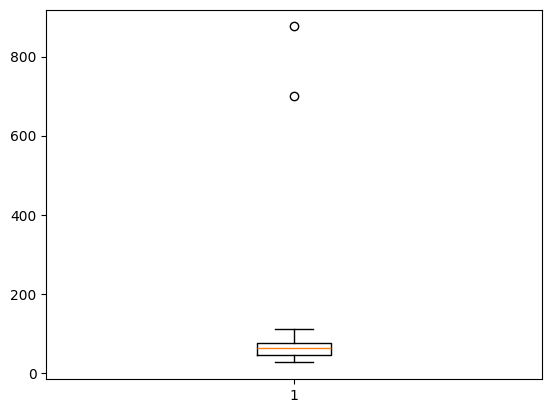

In [43]:
pd.to_numeric(all_hourly_values)
plt.boxplot(all_hourly_values)

In [44]:
all_hourly_values = [hourly for hourly in all_hourly_values if hourly <= 200]

In [45]:
all_hourly_values_series = pd.Series(all_hourly_values)
all_hourly_values_series.describe()

count     67.000000
mean      60.228387
std       18.505519
min       26.538462
25%       43.728846
50%       62.000000
75%       75.865385
max      111.538462
dtype: float64

#### Validate the Salary Outlier

The initial maximum was unusually high. We locate the corresponding job URL and compare the salary text with the linked job-detail page. Because that salary was not shown on the detail page, it is treated as an unverified anomaly and excluded from the final salary statistics while the raw scraped value remains unchanged.

In [46]:
salary_df["salary"]

1                           $69 Hourly
2          $55,200 - $120,330 Annually
3                    $90 - $100 Hourly
4         $124,000 - $139,000 Annually
5         $169,000 - $232,000 Annually
6         $107,203 - $160,805 Annually
7         $130,000 - $160,000 Annually
8         $130,000 - $160,000 Annually
9         $130,000 - $160,000 Annually
10        $130,000 - $160,000 Annually
11                    $65 - $80 Hourly
13        $100,000 - $135,000 Annually
14         $68,900 - $103,000 Annually
15                    $78 - $82 Hourly
16        $118,200 - $197,000 Annually
17                    $64,000 Annually
22         $86,000 - $138,000 Annually
23         $91,912 - $131,578 Annually
24         $85,034 - $168,266 Annually
29        $145,800 - $182,200 Annually
30    $1,458,000 - $1,822,000 Annually
31         $77,358 - $111,201 Annually
33         $87,700 - $157,800 Annually
34         $87,700 - $157,800 Annually
35                          $56 Hourly
36          $70,000 - $78

In [47]:
# Create salary_clean_df by keeping rows that do NOT contain "1,822,000"
salary_clean_df = salary_df.loc[~salary_df["salary"].str.contains("1,822,000", na=False)].copy()
salary_clean_df['salary']

1                       $69 Hourly
2      $55,200 - $120,330 Annually
3                $90 - $100 Hourly
4     $124,000 - $139,000 Annually
5     $169,000 - $232,000 Annually
6     $107,203 - $160,805 Annually
7     $130,000 - $160,000 Annually
8     $130,000 - $160,000 Annually
9     $130,000 - $160,000 Annually
10    $130,000 - $160,000 Annually
11                $65 - $80 Hourly
13    $100,000 - $135,000 Annually
14     $68,900 - $103,000 Annually
15                $78 - $82 Hourly
16    $118,200 - $197,000 Annually
17                $64,000 Annually
22     $86,000 - $138,000 Annually
23     $91,912 - $131,578 Annually
24     $85,034 - $168,266 Annually
29    $145,800 - $182,200 Annually
31     $77,358 - $111,201 Annually
33     $87,700 - $157,800 Annually
34     $87,700 - $157,800 Annually
35                      $56 Hourly
36      $70,000 - $78,500 Annually
37                $57 - $62 Hourly
38                $57 - $62 Hourly
39    $100,000 - $140,000 Annually
40     $70,000 - $10

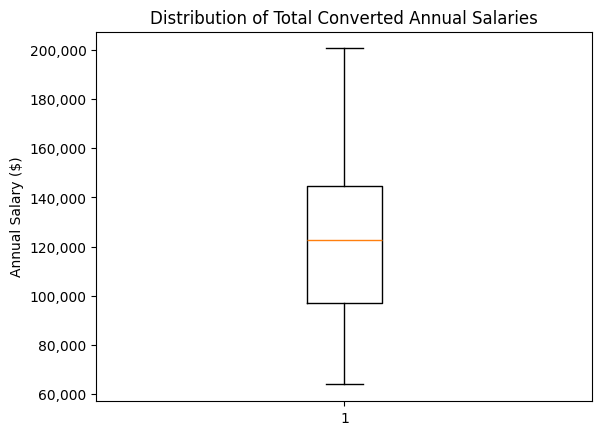

In [48]:
# ==========================================
# 1. PROCESS THE HOURLY ROLES
# ==========================================
# Filter hourly rows
hourly_jobs_df = salary_clean_df.loc[salary_clean_df["salary"].str.contains("Hourly", case=False, na=False)]

# Extract numbers
salary_clean_df[["min_hourly", "max_hourly"]] = hourly_jobs_df["salary"].str.extract(r"\$(\d+)(?:\s*-\s*\$(\d+))?")

# Convert text to numeric floats
min_hourly_num = pd.to_numeric(salary_clean_df["min_hourly"], errors="coerce")
max_hourly_num = pd.to_numeric(salary_clean_df["max_hourly"], errors="coerce")

# Convert to an annual rate (Hourly * 1800)
hourly_converted_min = min_hourly_num * 1800
hourly_converted_max = max_hourly_num * 1800


# ==========================================
# 2. PROCESS THE ANNUAL ROLES
# ==========================================
# Filter annual rows
annual_jobs_df = salary_clean_df.loc[salary_clean_df["salary"].str.contains("Annually", case=False, na=False)]

# Extract numbers (handles commas)
pattern = r"\$([\d,]+)(?:\s*-\s*\$([\d,]+))?"
extracted_annual = annual_jobs_df["salary"].str.extract(pattern)

# Clean out commas and convert text to numbers
salary_clean_df["min_annual"] = pd.to_numeric(extracted_annual[0].str.replace(",", ""), errors="coerce")
salary_clean_df["max_annual"] = pd.to_numeric(extracted_annual[1].str.replace(",", ""), errors="coerce")


# ==========================================
# 3. COMBINE BOTH DATASETS
# ==========================================
# Fill in missing annual data with the converted hourly calculations
salary_clean_df["min_annual"] = salary_clean_df["min_annual"].fillna(hourly_converted_min)
salary_clean_df["max_annual"] = salary_clean_df["max_annual"].fillna(hourly_converted_max)


# ==========================================
# 4. PREPARE & PLOT THE BOX PLOT 📦
# ==========================================
# Calculate a single average annual salary per row for the box plot
salary_clean_df["avg_annual_salary"] = salary_clean_df[["min_annual", "max_annual"]].mean(axis=1, skipna=True)

# Drop missing values so they don't crash Matplotlib
plot_data = salary_clean_df["avg_annual_salary"].dropna()

# Generate your box plot
plt.boxplot(plot_data)
plt.title("Distribution of Total Converted Annual Salaries")
plt.ylabel("Annual Salary ($)")

# Format the Y-axis numbers to look like currency (e.g., 80,000)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.show()

In [49]:
salary_clean_df.describe()

,min_annual,max_annual,avg_annual_salary
count,35.000000,32.00000,35.000000
mean,104275.657143,140735.62500,120602.685714
std,29453.916315,34212.69202,30735.234778
min,55200.000000,78500.00000,64000.000000
25%,80020.500000,111600.00000,97140.000000
50%,100800.000000,142000.00000,122750.000000
75%,130000.000000,160000.00000,144500.000000
max,169000.000000,232000.00000,200500.000000


In [50]:
def representative_salary(numbers):
    if len(numbers) == 1:
        return numbers[0]
    else:
        return sum(numbers) / len(numbers)

In [51]:
salary_clean_df["representative_hourly"] = salary_clean_df["hourly_numbers"].apply(
    representative_salary
)

In [52]:
salary_clean_df[
    ["salary", "hourly_numbers", "representative_hourly"]
].head(10)

,salary,hourly_numbers,representative_hourly
1,$69 Hourly,[69],69.000000
2,"$55,200 - $120,330 Annually","[26.53846153846154, 57.85096153846154]",42.194712
3,$90 - $100 Hourly,"[90, 100]",95.000000
4,"$124,000 - $139,000 Annually","[59.61538461538461, 66.82692307692308]",63.221154
5,"$169,000 - $232,000 Annually","[81.25, 111.53846153846153]",96.394231
6,"$107,203 - $160,805 Annually","[51.53990384615385, 77.31009615384616]",64.425000
7,"$130,000 - $160,000 Annually","[62.5, 76.92307692307692]",69.711538
8,"$130,000 - $160,000 Annually","[62.5, 76.92307692307692]",69.711538
9,"$130,000 - $160,000 Annually","[62.5, 76.92307692307692]",69.711538
10,"$130,000 - $160,000 Annually","[62.5, 76.92307692307692]",69.711538


In [53]:
median_hourly = salary_clean_df["representative_hourly"].median()

print("Median Hourly Rate: "+f"${median_hourly:,.2f}")

Median Hourly Rate: $59.50


### Most Frequent Job Locations

To identify where the job opportunities are most frequently located, we examined the frequency of each location in the scraped job postings.

In [54]:
rows = []

for card in cards:
    job = parse_job_card(card)
    rows.append(job)

jobs_df = pd.DataFrame(rows)

jobs_df.head()

,job_title,company,location,employment_type,salary,job_url
0,Business Data Analyst,None,"Hybrid Remote in Philadelphia, PA",[Temporary],NaN,https://remote.co/job-details/business-data-an...
1,Business Data Analyst,None,"Hybrid Remote in Plano, TX","[Full-Time, Temporary]",$69 Hourly,https://remote.co/job-details/business-data-an...
2,Business Data Analyst,None,"Hybrid Remote in Milwaukee, WI, Naperville, IL","[Full-Time, Employee]","$55,200 - $120,330 Annually",https://remote.co/job-details/business-data-an...
3,Business Data Analyst,None,"Remote in Milwaukee, WI",[Freelance],$90 - $100 Hourly,https://remote.co/job-details/business-data-an...
4,"Senior Business Data Analyst, Business Analytics",None,"Hybrid Remote in New York City, NY","[Full-Time, Employee]","$124,000 - $139,000 Annually",https://remote.co/job-details/senior-business-...


In [55]:
len(jobs_df)

50

In [56]:
jobs_df["location"].value_counts()

location
Remote, US National                                                                               19
Remote in MO, AR                                                                                   2
Hybrid Remote in Philadelphia, PA                                                                  1
Hybrid Remote in Plano, TX                                                                         1
Hybrid Remote in Milwaukee, WI, Naperville, IL                                                     1
Remote in Milwaukee, WI                                                                            1
Hybrid Remote in New York City, NY                                                                 1
Hybrid Remote in San Francisco, CA                                                                 1
Hybrid Remote in Canton, MA                                                                        1
Remote in Fort Belvoir, VA                                                        

#### Location Analysis

The most frequent location was **Remote, US National**, which appeared in 19 out of 50 collected job postings (38%). The second most frequent location was **Remote in MO, AR**, which appeared twice. All other listed locations appeared only once.

The results show that many postings were available nationally, while the remaining postings were distributed across specific U.S. cities/states and some international locations. Some postings were also classified as hybrid remote rather than fully remote.

### Q1(f) Conclusion: Are Remote Business Data Analyst Opportunities Plentiful and Well Paid?

The collected data provides some support for the conclusion that remote Business Data Analyst opportunities are plentiful and well paid, but there are important limitations.

In terms of job availability, Remote.co reported a large number of search results for "Business Data Analyst." Among the 50 postings collected for this analysis, 19 (38%) were listed as "Remote, US National." However, the 50 collected postings represent only a small portion of the reported search results. In addition, some postings were hybrid remote and the search results included related job titles rather than only exact Business Data Analyst positions. Therefore, the data suggests that opportunities exist, but it is not sufficient to conclude that exact remote Business Data Analyst positions are plentiful.

In terms of compensation, the saved search HTML contained salary text for 36 of 50 postings (72%). After manual validation identified one anomalous salary that was not present on its linked job-detail page, 35 of 50 postings (70%) had usable salary information for the salary analysis. After standardizing annual salaries to hourly rates using 2,080 work hours per year, the minimum advertised rate was approximately $26.54 per hour, the maximum was $111.54 per hour, and the median representative rate was $59.50 per hour. These results suggest relatively strong compensation among postings with usable salary information.

Overall, the results should be interpreted as a snapshot rather than a complete representation of the Remote.co job market because of the limited sample, broad search matching, variation in remote/hybrid arrangements, unavailable company names, and the salary anomaly identified during validation.

## Question 2 — 2024 ACS 5-Year California City Analysis

This section uses the **2024 American Community Survey (ACS) 5-year Data Profile API** to evaluate California cities for further market investigation.

## Census API Analysis

For this analysis, we will use the 2024 ACS 5-year data for California places. We will begin with population and median household income and add one additional demographic variable that may be relevant to market attractiveness.

### Additional Demographic Variable: Educational Attainment

We selected the percentage of the population age 25 and over with a bachelor's degree or higher as an additional measure of market attractiveness.

A higher percentage may indicate a larger pool of educated workers who could qualify for professional, analytical, technical, and management positions. This could make a city more attractive to businesses that need skilled employees.

In [57]:
# Set the 2024 URL
census_url = "https://api.census.gov/data/2024/acs/acs5/profile"

In [58]:
census_params = {
    "get": "NAME,DP05_0001E,DP03_0062E,DP02_0068PE",
    "for": "place:*",
    "in": "state:06",
    "key": "5c133fc39b4396a1ecac3510d01b28e62217c988"
}

In [59]:
# Sending API Request
census_response = requests.get(
    census_url,
    params=census_params,
    timeout=20
)

print("Status code:", census_response.status_code)
print("Final URL:")
print(census_response.url)

census_response.raise_for_status()

Status code: 200
Final URL:
https://api.census.gov/data/2024/acs/acs5/profile?get=NAME%2CDP05_0001E%2CDP03_0062E%2CDP02_0068PE&for=place%3A%2A&in=state%3A06&key=5c133fc39b4396a1ecac3510d01b28e62217c988


In [60]:
census_response.raise_for_status()

In [61]:
print(census_response.text[:500])

[["NAME","DP05_0001E","DP03_0062E","DP02_0068PE","state","place"],
["Acalanes Ridge CDP, California","1006","181094","70.2","06","00135"],
["Acampo CDP, California","234","-666666666","21.8","06","00156"],
["Acton CDP, California","7880","113000","29.9","06","00212"],
["Adelanto city, California","37964","68685","7.7","06","00296"],
["Adin CDP, California","153","29375","31.3","06","00310"],
["Agoura Hills city, California","19721","171302","67.5","06","00394"],
["Agua Dulce CDP, California","28


#### Inspect the API Response

The Census API returns JSON as a list of lists. The first row contains column names and the remaining rows contain place-level observations. I inspect the response before converting it to a DataFrame.

In [62]:
# Converting Json into Python
census_data = census_response.json()

print(type(census_data))
print("Number of rows including header:", len(census_data))

print("Header row:")
print(census_data[0])

print("First data row:")
print(census_data[1])

<class 'list'>
Number of rows including header: 1619
Header row:
['NAME', 'DP05_0001E', 'DP03_0062E', 'DP02_0068PE', 'state', 'place']
First data row:
['Acalanes Ridge CDP, California', '1006', '181094', '70.2', '06', '00135']


In [63]:
places_raw = pd.DataFrame(
    census_data[1:],
    columns=census_data[0]
)

print(places_raw.shape)
places_raw.head()

(1618, 6)


,NAME,DP05_0001E,DP03_0062E,DP02_0068PE,state,place
0,"Acalanes Ridge CDP, California",1006,181094,70.2,06,00135
1,"Acampo CDP, California",234,-666666666,21.8,06,00156
2,"Acton CDP, California",7880,113000,29.9,06,00212
3,"Adelanto city, California",37964,68685,7.7,06,00296
4,"Adin CDP, California",153,29375,31.3,06,00310


In [64]:
# Renaming the columns
places = places_raw.rename(columns={
    "NAME": "place_name",
    "DP05_0001E": "population",
    "DP03_0062E": "median_household_income",
    "DP02_0068PE": "bachelors_or_higher_pct",
    "state": "state_code",
    "place": "place_code"
}).copy()

places.head()

,place_name,population,median_household_income,bachelors_or_higher_pct,state_code,place_code
0,"Acalanes Ridge CDP, California",1006,181094,70.2,06,00135
1,"Acampo CDP, California",234,-666666666,21.8,06,00156
2,"Acton CDP, California",7880,113000,29.9,06,00212
3,"Adelanto city, California",37964,68685,7.7,06,00296
4,"Adin CDP, California",153,29375,31.3,06,00310


In [65]:
places.dtypes

place_name                 str
population                 str
median_household_income    str
bachelors_or_higher_pct    str
state_code                 str
place_code                 str
dtype: object

#### Convert Analysis Variables to Numeric Types

Census API values arrive as text. Population, median household income, and bachelor’s-degree percentage must be converted to numeric values before validation, filtering, and ranking.

In [66]:
# Converting the columns that should be numeric
places["population"] = pd.to_numeric(
    places["population"],
    errors="coerce"
)

places["median_household_income"] = pd.to_numeric(
    places["median_household_income"],
    errors="coerce"
)

places["bachelors_or_higher_pct"] = pd.to_numeric(
    places["bachelors_or_higher_pct"],
    errors="coerce"
)

places.dtypes

place_name                     str
population                   int64
median_household_income      int64
bachelors_or_higher_pct    float64
state_code                     str
place_code                     str
dtype: object

#### Validate Census Values

The Census data can contain special negative values such as `-666666666`, which indicate unavailable or non-usable estimates rather than real measurements. We also check that education percentages are between 0 and 100 and that population is positive.

In [67]:
places[places["median_household_income"] < 0][
    ["place_name", "median_household_income"]
]

,place_name,median_household_income
1,"Acampo CDP, California",-666666666
13,"Albion CDP, California",-666666666
14,"Alderpoint CDP, California",-666666666
18,"Alleghany CDP, California",-666666666
21,"Almanor CDP, California",-666666666
...,...,...
1584,"Wilsonia CDP, California",-666666666
1589,"Winterhaven CDP, California",-666666666
1606,"Yettem CDP, California",-666666666
1607,"Yolo CDP, California",-666666666


In [68]:
# Checking percentage of the population between 0 and 100
places[
    (places["bachelors_or_higher_pct"] < 0) |
    (places["bachelors_or_higher_pct"] > 100)
][["place_name", "bachelors_or_higher_pct"]]

,place_name,bachelors_or_higher_pct
21,"Almanor CDP, California",-666666666.0
95,"Belden CDP, California",-666666666.0
129,"Blairsden CDP, California",-666666666.0
164,"Brooks CDP, California",-666666666.0
167,"Buck Meadows CDP, California",-666666666.0
217,"Caribou CDP, California",-666666666.0
246,"Cedar Slope CDP, California",-666666666.0
255,"Charleston View CDP, California",-666666666.0
324,"Coulterville CDP, California",-666666666.0
335,"Creston CDP, California",-666666666.0


In [69]:
# Checking population
places[places["population"] <= 0][
    ["place_name", "population"]
]

,place_name,population
21,"Almanor CDP, California",0
95,"Belden CDP, California",0
129,"Blairsden CDP, California",0
164,"Brooks CDP, California",0
167,"Buck Meadows CDP, California",0
217,"Caribou CDP, California",0
246,"Cedar Slope CDP, California",0
255,"Charleston View CDP, California",0
324,"Coulterville CDP, California",0
335,"Creston CDP, California",0


#### Create a Clean Analysis Dataset

Rows without usable values for all three analysis variables are excluded from the candidate analysis. This keeps only positive population values, nonnegative household income values, and education percentages from 0 to 100.

In [70]:
places_clean = places[
    (places["population"] > 0) &
    (places["median_household_income"] >= 0) &
    (places["bachelors_or_higher_pct"] >= 0) &
    (places["bachelors_or_higher_pct"] <= 100)
].copy()

print("Original rows:", len(places))
print("Clean rows:", len(places_clean))

Original rows: 1618
Clean rows: 1375


#### Keep California Cities

The API response contains different types of California places, including CDPs. Because the assignment asks for cities, I retain place names containing `city, California`.

In [71]:
cities = places_clean[
    places_clean["place_name"].str.contains(" city, California")
].copy()

print("Number of cities:", len(cities))

cities.head()

Number of cities: 461


,place_name,population,median_household_income,bachelors_or_higher_pct,state_code,place_code
3,"Adelanto city, California",37964,68685,7.7,06,00296
5,"Agoura Hills city, California",19721,171302,67.5,06,00394
10,"Alameda city, California",77238,137697,61.5,06,00562
12,"Albany city, California",19414,144107,77.8,06,00674
15,"Alhambra city, California",81022,88024,40.8,06,00884


#### Summarize the City Dataset

Descriptive statistics provide context for the distribution of population, household income, and educational attainment before selecting candidates.

In [72]:
cities[
    ["place_name", "population", 
     "median_household_income", "bachelors_or_higher_pct"]
].describe()

,population,median_household_income,bachelors_or_higher_pct
count,4.610000e+02,461.000000,461.000000
mean,7.048364e+04,103727.763557,35.070933
std,2.082085e+05,44152.223704,20.792069
min,1.740000e+02,28839.000000,1.500000
25%,1.204400e+04,73571.000000,17.100000
50%,3.181400e+04,93810.000000,30.900000
75%,7.681900e+04,122951.000000,49.500000
max,3.857263e+06,250001.000000,88.400000


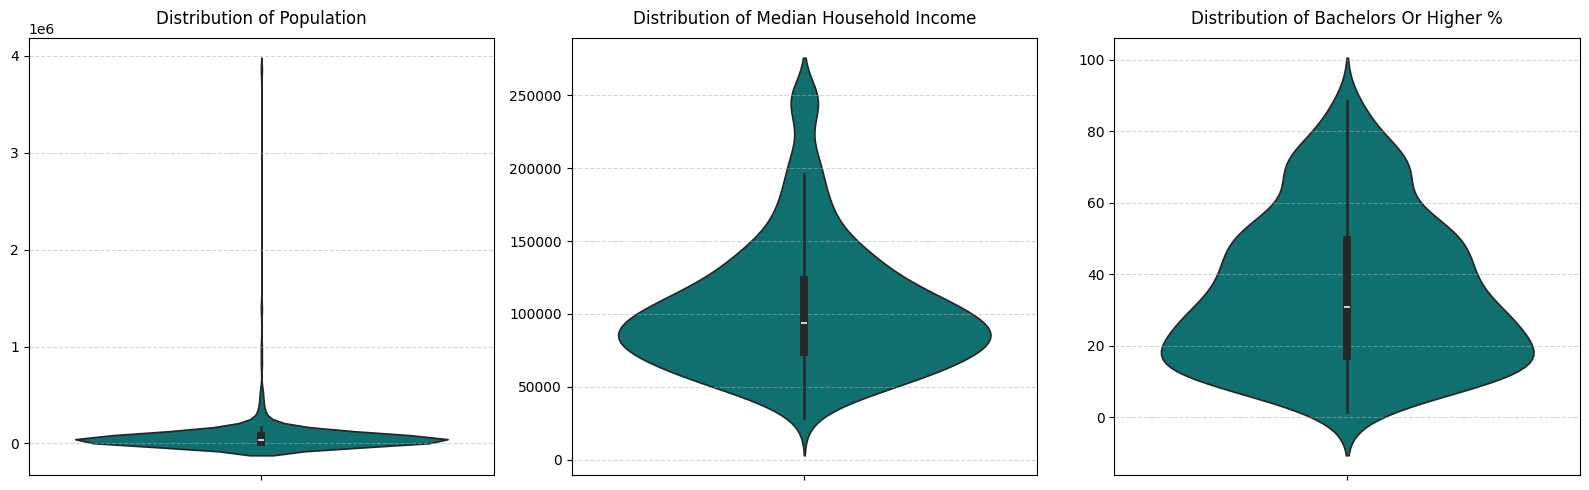

In [79]:
# Define numerical columns to visualize
columns_to_plot = ["population", "median_household_income", "bachelors_or_higher_pct"]

# Setup a clean 1x3 subplot grid
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(columns_to_plot):
    # 'inner="box"' adds a miniature boxplot inside each violin
    sns.violinplot(data=cities, y=col, ax=axes[i], color="teal", inner="box")
    
    # Format titles and remove redundant y-labels
    clean_title = col.replace('_', ' ').title().replace('Pct', '%')
    axes[i].set_title(f"Distribution of {clean_title}", fontsize=12, pad=10)
    axes[i].set_ylabel("")
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### Compare Cities on Each Variable

The next three tables show the leading cities separately by population, median household income, and educational attainment. This helps show why selecting a city from only one measure could be misleading.

In [80]:
# cities with the largest populations
cities[
    ["place_name", "population",
     "median_household_income", "bachelors_or_higher_pct"]
].sort_values(
    "population", ascending=False
).head(10)

,place_name,population,median_household_income,bachelors_or_higher_pct
843,"Los Angeles city, California",3857263,81939,38.5
1266,"San Diego city, California",1389526,108077,51.0
1276,"San Jose city, California",990138,146427,47.3
1270,"San Francisco city, California",830235,140970,60.3
533,"Fresno city, California",545970,70991,25.5
1246,"Sacramento city, California",528706,87321,37.1
836,"Long Beach city, California",455548,87430,35.6
1031,"Oakland city, California",439418,101600,48.7
75,"Bakersfield city, California",411986,80540,23.6
37,"Anaheim city, California",344521,95227,29.7


In [81]:
# cities with the highest median household income
cities[
    ["place_name", "population",
     "median_household_income", "bachelors_or_higher_pct"]
].sort_values(
    "median_household_income", ascending=False
).head(10)

,place_name,population,median_household_income,bachelors_or_higher_pct
841,"Los Altos city, California",30698,250001,88.1
102,"Belvedere city, California",2345,250001,87.4
958,"Monte Sereno city, California",3461,250001,84.7
1061,"Orinda city, California",19514,250001,85.9
1115,"Piedmont city, California",10945,250001,88.4
626,"Hidden Hills city, California",2150,250001,72.2
1224,"Rolling Hills city, California",1509,250001,76.2
1312,"Saratoga city, California",30319,250001,81.1
1080,"Palos Verdes Estates city, California",12925,242014,79.6
722,"La Cañada Flintridge city, California",19935,241875,75.1


In [82]:
# Cities with the highest percentage of adults age 25+ with a bachelor's degree or higher
cities[
    ["place_name", "population",
     "median_household_income", "bachelors_or_higher_pct"]
].sort_values(
    "bachelors_or_higher_pct", ascending=False
).head(10)

,place_name,population,median_household_income,bachelors_or_higher_pct
1115,"Piedmont city, California",10945,250001,88.4
841,"Los Altos city, California",30698,250001,88.1
102,"Belvedere city, California",2345,250001,87.4
364,"Del Mar city, California",3903,199152,86.4
1061,"Orinda city, California",19514,250001,85.9
958,"Monte Sereno city, California",3461,250001,84.7
1284,"San Marino city, California",12216,214167,82.6
1077,"Palo Alto city, California",67237,231101,82.3
343,"Cupertino city, California",58566,234707,82.2
1312,"Saratoga city, California",30319,250001,81.1


#### Build a Balanced Candidate Set

Because the goal is to consider all three measures, I first keep cities that are above the city mean for **population, median household income, and bachelor’s degree or higher percentage**. This produces a smaller set of balanced candidates.

In [83]:
candidate_cities = cities[
    (cities["population"] > cities["population"].mean()) &
    (cities["median_household_income"] > cities["median_household_income"].mean()) &
    (cities["bachelors_or_higher_pct"] > cities["bachelors_or_higher_pct"].mean())
].copy()

print("Number of candidate cities:", len(candidate_cities))

Number of candidate cities: 47


#### Rank the Candidate Cities

Each candidate is ranked separately on the three measures, with rank 1 representing the highest value. The three ranks are then averaged with equal weight. A **lower average rank is better** because it indicates stronger overall performance across the measures.

In [84]:
candidate_cities["population_rank"] = candidate_cities["population"].rank(
    ascending=False
)

candidate_cities["income_rank"] = candidate_cities["median_household_income"].rank(
    ascending=False
)

candidate_cities["education_rank"] = candidate_cities["bachelors_or_higher_pct"].rank(
    ascending=False
)

In [85]:
candidate_cities[
    ["place_name",
     "population_rank",
     "income_rank",
     "education_rank"]
].head(10)

,place_name,population_rank,income_rank,education_rank
10,"Alameda city, California",42.0,18.0,13.0
109,"Berkeley city, California",20.0,40.0,2.0
218,"Carlsbad city, California",21.0,15.0,12.0
267,"Chino Hills city, California",41.0,23.0,28.0
308,"Concord city, California",19.0,39.0,45.5
319,"Costa Mesa city, California",23.0,37.0,32.0
349,"Daly City city, California",25.0,26.0,41.5
402,"Dublin city, California",46.0,1.0,7.0
431,"Eastvale city, California",47.0,10.0,36.0
450,"Elk Grove city, California",8.0,24.0,41.5


In [129]:
candidate_cities["average_rank"] = (
    candidate_cities["population_rank"] +
    candidate_cities["income_rank"] +
    candidate_cities["education_rank"]
) / 3

In [130]:
candidate_cities[
    ["place_name", "population",
     "median_household_income", "bachelors_or_higher_pct",
     "population_rank", "income_rank",
     "education_rank", "average_rank"]
].sort_values(
    "average_rank", ascending=True
).head(10)

,place_name,population,median_household_income,bachelors_or_higher_pct,population_rank,income_rank,education_rank,average_rank
529,"Fremont city, California",228295,181506,63.9,6.0,6.0,11.0,7.666667
1414,"Sunnyvale city, California",154236,186170,69.3,11.0,5.0,9.0,8.333333
675,"Irvine city, California",311690,136719,70.6,4.0,19.0,5.0,9.333333
1296,"Santa Clara city, California",130256,178958,65.9,16.0,7.0,10.0,11.000000
1270,"San Francisco city, California",830235,140970,60.3,3.0,16.0,14.0,11.000000
1292,"San Ramon city, California",85993,196161,71.6,31.0,2.0,3.0,12.000000
978,"Mountain View city, California",83732,189917,75.0,35.0,4.0,1.0,13.333333
1276,"San Jose city, California",990138,146427,47.3,2.0,14.0,31.0,15.666667
218,"Carlsbad city, California",114373,142748,62.1,21.0,15.0,12.0,16.000000
1138,"Pleasanton city, California",76960,190124,69.9,43.0,3.0,6.0,17.333333


In [131]:
top_3_cities = candidate_cities[
    ["place_name", "population",
     "median_household_income", "bachelors_or_higher_pct",
     "average_rank"]
].sort_values(
    "average_rank", ascending=True
).head(3)

top_3_cities

,place_name,population,median_household_income,bachelors_or_higher_pct,average_rank
529,"Fremont city, California",228295,181506,63.9,7.666667
1414,"Sunnyvale city, California",154236,186170,69.3,8.333333
675,"Irvine city, California",311690,136719,70.6,9.333333


In [132]:
house_costs = pd.read_excel('/Users/noracook/Documents/BAN 612/Week 4/california_house_prices_2020.xlsx')

In [133]:
house_costs

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,CountyName,2020-01-31 00:00:00
0,12447,1,Los Angeles,city,CA,CA,"Los Angeles-Long Beach-Anaheim, CA",Los Angeles County,7.296358e+05
1,54296,8,San Diego,city,CA,CA,"San Diego-Chula Vista-Carlsbad, CA",San Diego County,6.579895e+05
2,33839,11,San Jose,city,CA,CA,"San Jose-Sunnyvale-Santa Clara, CA",Santa Clara County,9.771196e+05
3,20330,17,San Francisco,city,CA,CA,"San Francisco-Oakland-Berkeley, CA",San Francisco County,1.344442e+06
4,20288,28,Sacramento,city,CA,CA,"Sacramento-Roseville-Folsom, CA",Sacramento County,3.690257e+05
...,...,...,...,...,...,...,...,...,...
954,23633,28521,Bear Valley,city,CA,CA,NaN,Alpine County,3.355695e+05
955,12132,28521,Johannesburg,city,CA,CA,"Riverside-San Bernardino-Ontario, CA",San Bernardino County,8.541621e+04
956,8442,28521,Kirkwood,city,CA,CA,NaN,Alpine County,4.707322e+05
957,396499,28521,Plumas Eureka,city,CA,CA,NaN,Plumas County,3.188800e+05


In [152]:
house_costs.columns.to_list()

['RegionID',
 'SizeRank',
 'place_name',
 'RegionType',
 'StateName',
 'State',
 'Metro',
 'CountyName',
 'jan_2020']

In [153]:
# Rename the column and update the DataFrame in place
house_costs.rename(
    columns={"RegionName":"place_name", datetime.datetime(2020, 1, 31, 0, 0): 'jan_2020'}, 
    inplace=True
)

In [154]:
cities_house_costs = house_costs[["place_name", "jan_2020"]]
cities_house_costs

cities_house_costs.dropna(inplace=True)
cities_house_costs.style.format({'jan_2020': '{:,.1f}'}) 

,place_name,jan_2020
0,Los Angeles,"729,635.8"
1,San Diego,"657,989.5"
2,San Jose,"977,119.6"
3,San Francisco,"1,344,442.3"
4,Sacramento,"369,025.7"
5,Fresno,"267,743.1"
6,Long Beach,"615,560.0"
7,Bakersfield,"253,939.8"
8,Oakland,"785,607.2"
9,Riverside,"438,457.2"


In [155]:
cities['place_name'] = cities['place_name'].str.extract(r'^(.*?)\s+city', expand=False)


In [157]:
merged_df = cities.merge(cities_house_costs, on="place_name", how="left") 
merged_df

,place_name,population,median_household_income,bachelors_or_higher_pct,state_code,place_code,jan_2020
0,NaN,37964,68685,7.7,06,00296,NaN
1,NaN,19721,171302,67.5,06,00394,NaN
2,NaN,77238,137697,61.5,06,00562,NaN
3,NaN,19414,144107,77.8,06,00674,NaN
4,NaN,81022,88024,40.8,06,00884,NaN
...,...,...,...,...,...,...,...
456,NaN,67170,157582,56.2,06,86832,NaN
457,NaN,3348,80342,41.6,06,86930,NaN
458,NaN,7820,43982,19.0,06,86944,NaN
459,NaN,69471,75477,20.4,06,86972,NaN


In [148]:
merged_df
merged_df.style.format({'jan_2020': '{:,.1f}'}) 

,place_name,population,median_household_income,bachelors_or_higher_pct,state_code,place_code,jan_2020
0,nan,37964,68685,7.700000,06,00296,nan
1,nan,19721,171302,67.500000,06,00394,nan
2,nan,77238,137697,61.500000,06,00562,nan
3,nan,19414,144107,77.800000,06,00674,nan
4,nan,81022,88024,40.800000,06,00884,nan
5,nan,51113,142439,57.600000,06,00947,nan
6,nan,2681,59896,32.800000,06,01444,nan
7,nan,174,107917,51.000000,06,01514,nan
8,nan,21691,121700,32.700000,06,01640,nan
9,nan,344521,95227,29.700000,06,02000,nan


In [149]:
candidate_cities2 = merged_df[
    (merged_df["population"] > merged_df["population"].mean()) &
    (merged_df["median_household_income"] > merged_df["median_household_income"].mean()) &
    (merged_df["bachelors_or_higher_pct"] > merged_df["bachelors_or_higher_pct"].mean()) &
    (merged_df["jan_2020"] < merged_df["jan_2020"].mean())            
].copy()

print("Number of candidate cities:", len(candidate_cities))

Number of candidate cities: 47


In [ ]:
candidate_cities["population_rank"] = candidate_cities["population"].rank(
    ascending=False
)

candidate_cities["income_rank"] = candidate_cities["median_household_income"].rank(
    ascending=False
)

candidate_cities["education_rank"] = candidate_cities["bachelors_or_higher_pct"].rank(
    ascending=False
)
